# Processamento de imagens de TEM - Restauração e realce de imagem (em foco)
### Manipulação de dados, gradiente integrado e restauração iterativa
>Autor: Abraham Contreras

## Como usar

Este notebook foi adaptado para **imagens de microscopia eletrônica de transmissão (TEM) 2D**, como `CG_059.tif` (2048 × 2048 pixels).

|imagem TEM |
|---|
 | Correção do fundo de iluminação e remoção de pixels quentes |
 | Espectro de potência (FFT) da imagem |
 | Raio de corte do sinal no espaço de Fourier e calibração pela barra de escala |
 | Imagens virtuais por filtros circular (passa-baixa) e anular (passa-faixa) no espaço de Fourier |
| Recorte da região de interesse (ROI) e binning |
| Campo de gradiente da imagem e integração por Fourier (DPC) |
 | Restauração iterativa Richardson-Lucy com regularização TV (PSF estimada pelo espectro) |
| FFT antes e depois da restauração |

**Passos**

1. Coloque este notebook e a imagem (`CG_059.tif` ou semelhante) **na mesma pasta**. Os caminhos são calculados automaticamente a partir da pasta do próprio notebook; para outra imagem, troque apenas `nome_imagem` na célula de caminhos.
2. Execute as células **na ordem, de cima para baixo**.
3. Parâmetros que você pode ajustar estão agrupados em células curtas: `comprimento_barra_nm` / `tamanho_pixel_nm` (calibração), `periodo_BF` (separação campo claro/escuro), `ROI1` (recorte), `parametros_scientific` e `parametros_visual` (processamento) e `psf_sigma` / `tv_denoise_weight` (restauração).
4. O OpenCV (`cv2`) é opcional: se não estiver instalado, o notebook usa alternativas do scikit-image.

# Agradecimentos e ressalvas

In [5]:
# Este tutorial foi adaptado por Abraham Contreras(guzmanabraham108@gmail.com)
# para imagens de TEM 2D:

# Não está totalmente otimizado.
# Seu objetivo é mostrar que funciona e que é divertido de usar!

In [2]:
# Amostra cedida por cortesia da Jessika Nobrega, da Ilum Escola de Ciência

**Se for util para você cite:**

>CONTRERAS, Abraham. Processamento de imagens de TEM: restauração e realce de imagem (em foco) – manipulação de dados, gradiente integrado e restauração iterativa. Código computacional.

# Início

In [4]:
# Importação das bibliotecas

import os
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import patches
from matplotlib.colors import hsv_to_rgb
from types import SimpleNamespace

import tifffile
import scipy
from scipy import ndimage
from scipy.signal import fftconvolve
from scipy.special import expit

import skimage
from skimage import exposure, restoration

# OpenCV é opcional: acelera a redução de ruído (Non-Local Means) e o CLAHE
try:
    import cv2
except ImportError:
    cv2 = None
    print('Aviso: OpenCV (cv2) não encontrado; serão usadas alternativas do scikit-image.')

# As bibliotecas do fluxo 4D-STEM (py4DSTEM, h5py, hdf5plugin) não são necessárias para imagens de TEM 2D.

In [5]:
# Definição dos caminhos do conjunto de dados

import os
from pathlib import Path


def obter_pasta_do_notebook():
    """Retorna a pasta onde este arquivo .ipynb está salvo."""

    # VS Code
    arquivo_vscode = globals().get('__vsc_ipynb_file__')
    if arquivo_vscode:
        return Path(arquivo_vscode).resolve().parent

    # JupyterLab / Jupyter Notebook
    sessao = os.environ.get('JPY_SESSION_NAME')
    if sessao and Path(sessao).is_absolute() and Path(sessao).exists():
        return Path(sessao).resolve().parent

    # Execução como script .py
    if '__file__' in globals():
        return Path(__file__).resolve().parent

    # Diretório de trabalho atual
    return Path.cwd().resolve()


# Pasta do notebook: todas as imagens devem estar nesta mesma pasta
pasta_notebook = obter_pasta_do_notebook()
print('Pasta do notebook (e das imagens):', pasta_notebook)

# Pasta (a mesma pasta do notebook, com separador final)
file_path = str(pasta_notebook) + os.sep

# Nome da imagem de TEM. Para analisar outra imagem semelhante, troque apenas o nome.
nome_imagem = 'CG_059.tif'
filename = file_path + nome_imagem

# Outras imagens semelhantes disponíveis na mesma pasta
print('Imagens CG_*.tif* encontradas na pasta:', sorted(p.name for p in pasta_notebook.glob('CG_*.tif*')))

# Verificação do arquivo
if not os.path.isfile(filename):
    raise FileNotFoundError(
        'Imagem não encontrada: ' + filename + '\n'
        'Coloque o arquivo ' + nome_imagem + ' na mesma pasta deste notebook.'
    )
print(nome_imagem + ': encontrado')

Pasta do notebook (e das imagens): C:\JupyterLab\2-semestre\IP1\Jessika
Imagens CG_*.tif* encontradas na pasta: ['CG_059.tif', 'CG_059_PLUS.tif', 'CG_059_PLUS_PLUS_PLUS_PLUS.tif', 'CG_059_PLUS_SCIENTIFIC.tif', 'CG_059_PLUS_VISUAL.tif', 'CG_059_processada.tif']
CG_059.tif: encontrado


# Funções auxiliares
As células a seguir apenas definem funções (não processam a imagem).

In [6]:
# Funções auxiliares (1/3): leitura da imagem, barra de escala e máscara de validade

def ler_imagem_tem(caminho):
    """Lê um TIFF de TEM e devolve uma imagem 2D, preservando o tipo de dado original."""
    imagem = np.squeeze(tifffile.imread(str(caminho)))
    if imagem.ndim == 3 and imagem.shape[-1] in (3, 4):
        # Imagem RGB(A): converte para tons de cinza
        imagem = imagem[..., :3].mean(axis=-1).astype(imagem.dtype)
    elif imagem.ndim == 3:
        print('Aviso: o arquivo contém', imagem.shape[0], 'quadros; usando apenas o primeiro.')
        imagem = imagem[0]
    if imagem.ndim != 2:
        raise ValueError('A imagem deve ser bidimensional; forma lida: ' + str(imagem.shape))
    return imagem


def detectar_barra_de_escala(imagem, fracao_linhas=0.15, fracao_colunas=0.5):
    """
    Procura, nos cantos inferiores, o retângulo branco com a barra de escala gravada na imagem
    pelo software do microscópio. Devolve um dicionário com a caixa (r0, r1, c0, c1) e o
    comprimento da barra em pixels, ou None se nada for encontrado.
    """
    h, w = imagem.shape
    if np.issubdtype(imagem.dtype, np.integer):
        maximo = float(np.iinfo(imagem.dtype).max)
    else:
        maximo = float(np.max(imagem))
    limite_branco, limite_escuro = 0.97 * maximo, 0.25 * maximo

    r_ini = int(h * (1 - fracao_linhas))
    largura = int(w * fracao_colunas)
    for lado, (c_ini, c_fim) in (('esquerda', (0, largura)), ('direita', (w - largura, w))):
        regiao = imagem[r_ini:, c_ini:c_fim]
        branco = regiao >= limite_branco
        rotulos, n = ndimage.label(branco)
        if n == 0:
            continue
        areas = ndimage.sum(branco, rotulos, index=np.arange(1, n + 1))
        k = int(np.argmax(areas)) + 1
        if areas[k - 1] < 2000:
            continue
        fatia = ndimage.find_objects((rotulos == k).astype(int))[0]
        r0, r1 = fatia[0].start + r_ini, fatia[0].stop + r_ini
        c0, c1 = fatia[1].start + c_ini, fatia[1].stop + c_ini

        # A barra de escala é a maior sequência horizontal de pixels escuros dentro do retângulo
        escuro = imagem[r0:r1, c0:c1] <= limite_escuro
        melhor, linha = 0, 0
        for i in range(escuro.shape[0]):
            if not escuro[i].any():
                continue
            dif = np.diff(np.concatenate(([0], escuro[i].astype(np.int8), [0])))
            comprimento = int((np.flatnonzero(dif == -1) - np.flatnonzero(dif == 1)).max())
            if comprimento > melhor:
                melhor, linha = comprimento, i
        if melhor >= 30:
            return {'lado': lado, 'caixa': (r0, r1, c0, c1),
                    'comprimento_px': melhor, 'linha_barra': r0 + linha}
    return None


def construir_mascara_valida(forma, barra, margem=8):
    """Máscara booleana (True = pixel válido). Exclui o retângulo da barra de escala."""
    mascara = np.ones(forma, dtype=bool)
    if barra is not None:
        r0, r1, c0, c1 = barra['caixa']
        mascara[max(r0 - margem, 0):r1 + margem, max(c0 - margem, 0):c1 + margem] = False
    return mascara


def preencher_regiao_invalida(imagem, mascara_valida, ruido=0.0, semente=0):
    """
    Preenche a região inválida (barra de escala) com o fundo vizinho, por convolução
    normalizada em várias escalas, e adiciona ruído gaussiano com o desvio informado.
    """
    img = imagem.astype(np.float32).copy()
    if mascara_valida.all():
        return img
    invalida = ~mascara_valida
    pesos = mascara_valida.astype(np.float32)
    preenchido = np.zeros(img.shape, dtype=bool)
    # Trabalha em resolução reduzida (blocos de 8x8) para ser rápido
    f = 8
    h, w = img.shape
    hh, ww = (h // f) * f, (w // f) * f
    pequena = (img[:hh, :ww] * pesos[:hh, :ww]).reshape(hh // f, f, ww // f, f).sum(axis=(1, 3))
    peso_p = pesos[:hh, :ww].reshape(hh // f, f, ww // f, f).sum(axis=(1, 3))
    for sigma in (3, 8, 20, 50):
        num = ndimage.gaussian_filter(pequena, sigma, mode='nearest')
        den = ndimage.gaussian_filter(peso_p, sigma, mode='nearest')
        estimativa = np.where(den > 1e-3 * f * f, num / np.maximum(den, 1e-6), np.nan)
        grande = ndimage.zoom(np.nan_to_num(estimativa, nan=-1), f, order=1)
        grande = np.pad(grande, ((0, h - hh), (0, w - ww)), mode='edge')
        usar = invalida & ~preenchido & (grande > 0)
        img[usar] = grande[usar]
        preenchido |= usar
    restante = invalida & ~preenchido
    if restante.any():
        img[restante] = float(np.median(img[mascara_valida]))
    if ruido > 0:
        img[invalida] += np.random.default_rng(semente).normal(0, ruido, int(invalida.sum())).astype(np.float32)
    return img

In [7]:
# Funções auxiliares (2/3): ruído, correção de fundo, pixels quentes e processamento em etapas

def estimar_ruido(imagem, mascara=None):
    """Desvio padrão do ruído (método robusto baseado no resíduo do laplaciano de 3x3)."""
    nucleo = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    residuo = ndimage.convolve(imagem.astype(np.float32), nucleo, mode='reflect')
    if mascara is not None:
        residuo = residuo[ndimage.binary_erosion(mascara, iterations=3)]
    mad = np.median(np.abs(residuo - np.median(residuo)))
    return float(1.4826 * mad / 6.0)


def estimar_fundo_polinomial(imagem, mascara_valida, ordem=3, fator=16, n_iter=8, k_baixo=1.5, k_alto=3.0):
    """
    Estima o fundo de iluminação (vinheta/inclinação) ajustando um polinômio 2D em resolução reduzida,
    com rejeição iterativa dos pixels do espécime (mais escuros) e de valores muito claros.
    """
    h, w = imagem.shape
    hb, wb = h // fator, w // fator
    bloco = imagem[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    val = mascara_valida[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    n_val = val.sum(axis=(1, 3))
    media = (bloco * val).sum(axis=(1, 3)) / np.maximum(n_val, 1)
    valido = n_val >= 0.9 * fator * fator

    def termos(yy, xx):
        return [xx ** i * yy ** j for i in range(ordem + 1) for j in range(ordem + 1 - i)]

    yy, xx = np.meshgrid((np.arange(hb) + 0.5) / hb * 2 - 1, (np.arange(wb) + 0.5) / wb * 2 - 1, indexing='ij')
    A = np.stack([t[valido] for t in termos(yy, xx)], axis=1)
    b = media[valido]
    usar = np.ones_like(b, dtype=bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[usar], b[usar], rcond=None)[0]
        residuo = b - A @ coef
        sigma = 1.4826 * np.median(np.abs(residuo[usar] - np.median(residuo[usar])))
        usar = (residuo > -k_baixo * sigma) & (residuo < k_alto * sigma)
    Y, X = np.meshgrid((np.arange(h) + 0.5) / h * 2 - 1, (np.arange(w) + 0.5) / w * 2 - 1, indexing='ij')
    fundo = sum(c * t for c, t in zip(coef, termos(Y, X)))
    return fundo.astype(np.float32)


def remover_pixels_quentes(imagem, limiar_sigma=6.0, mascara=None):
    """Substitui pixels isolados muito diferentes da mediana 3x3 (raios X, pixels defeituosos)."""
    mediana = ndimage.median_filter(imagem, size=3, mode='reflect')
    residuo = imagem - mediana
    sigma = estimar_ruido(imagem, mascara)
    quentes = np.abs(residuo) > limiar_sigma * max(sigma, 1e-6)
    resultado = imagem.copy()
    resultado[quentes] = mediana[quentes]
    return resultado, int(quentes.sum())


def normalizar_percentis(imagem, percentis=(0.5, 99.7), mascara=None):
    """
    Ajusta a faixa tonal usando percentis.
    Evita que poucos pixels extremos dominem o contraste.
    """
    referencia = imagem if mascara is None else imagem[mascara]
    p_low, p_high = np.percentile(referencia, percentis)
    resultado = (imagem - p_low) / max(p_high - p_low, 1e-8)
    return np.clip(resultado, 0, 1).astype(np.float32)


def reduzir_ruido(imagem, intensidade):
    """
    Redução de ruído Non-Local Means (OpenCV). A operação é realizada em uint8.
    Sem OpenCV, usa variação total (Chambolle) como alternativa.
    """
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        resultado = cv2.fastNlMeansDenoising(imagem_uint8, None, h=float(intensidade),
                                             templateWindowSize=7, searchWindowSize=21)
        return resultado.astype(np.float32) / 255.0
    peso = 2.0 * float(intensidade) / 255.0
    return np.clip(restoration.denoise_tv_chambolle(imagem, weight=peso), 0, 1).astype(np.float32)


def aplicar_clahe(imagem, limite, grade):
    """Realce adaptativo de contraste local."""
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        clahe = cv2.createCLAHE(clipLimit=limite, tileGridSize=grade)
        return clahe.apply(imagem_uint8).astype(np.float32) / 255.0
    h, w = imagem.shape
    return exposure.equalize_adapthist(np.clip(imagem, 0, 1), kernel_size=(h // grade[0], w // grade[1]),
                                       clip_limit=limite / 100.0).astype(np.float32)


def suavizacao_controlada(imagem, intensidade, sigma=0.7):
    """Combina a imagem com uma versão suavizada. Mantém parte da textura."""
    suavizada = ndimage.gaussian_filter(imagem, sigma)
    resultado = (1 - intensidade) * imagem + intensidade * suavizada
    return np.clip(resultado, 0, 1).astype(np.float32)


def nitidez_controlada(imagem, intensidade, sigma):
    """Unsharp Mask: realça detalhes sem substituir a imagem."""
    borrada = ndimage.gaussian_filter(imagem, sigma)
    resultado = imagem + intensidade * (imagem - borrada)
    return np.clip(resultado, 0, 1).astype(np.float32)


def equilibrar_tons(imagem, percentis=(0.2, 99.8), mascara=None):
    """Ajuste tonal final."""
    return normalizar_percentis(imagem, percentis, mascara)


def processar_imagem(imagem, parametros, mascara=None):
    """Processamento em etapas (balanço tonal -> gama -> ruído -> CLAHE -> suavização -> nitidez -> tons)."""
    dataset_balance = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    dataset_gamma = np.power(dataset_balance, parametros['gamma']).astype(np.float32)

    h_nlm = parametros['denoise_strength']
    if h_nlm == 'auto':
        # força do filtro proporcional ao ruído medido (em níveis de 0 a 255)
        h_nlm = parametros['denoise_fator'] * 255.0 * estimar_ruido(dataset_gamma, mascara)
    dataset_denoised = reduzir_ruido(dataset_gamma, h_nlm)

    dataset_clahe = aplicar_clahe(dataset_denoised, parametros['clahe_limit'], parametros['clahe_grid'])
    dataset_smooth = suavizacao_controlada(dataset_clahe, parametros['smooth_strength'], parametros['smooth_sigma'])
    dataset_sharp = nitidez_controlada(dataset_smooth, parametros['sharp_strength'], parametros['sharp_sigma'])
    dataset_final = equilibrar_tons(dataset_sharp, parametros['final_percentiles'], mascara)
    return {'balance': dataset_balance, 'gamma': dataset_gamma, 'denoised': dataset_denoised,
            'clahe': dataset_clahe, 'smooth': dataset_smooth, 'sharp': dataset_sharp,
            'final': dataset_final, 'h_nlm': float(h_nlm)}

In [8]:
# Funções auxiliares (3/3): espectro de potência, perfil radial e visualização

def espectro_de_potencia(imagem):
    """Espectro de potência (FFT centrada) com janela de Hann, para evitar artefatos de borda."""
    img = imagem.astype(np.float32) - float(imagem.mean())
    janela = np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1])).astype(np.float32)
    F = np.fft.fftshift(np.fft.fft2(img * janela))
    return np.abs(F).astype(np.float64) ** 2


def perfil_radial(array2d, centro=None):
    """Média azimutal em função do raio (em pixels) em torno do centro (linha, coluna)."""
    h, w = array2d.shape
    cy, cx = (h // 2, w // 2) if centro is None else centro
    y, x = np.indices(array2d.shape)
    r = np.hypot(y - cy, x - cx).astype(np.int32).ravel()
    soma = np.bincount(r, weights=array2d.ravel())
    cont = np.bincount(r)
    return soma / np.maximum(cont, 1)


def _comprimento_barra_agradavel(largura_nm):
    candidatos = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000], dtype=float)
    return float(candidatos[np.argmin(np.abs(candidatos - 0.2 * largura_nm))])


def adicionar_barra_de_escala(eixo, pixel_nm, largura_px):
    """Desenha uma barra de escala em nm (ou µm) no canto inferior esquerdo do eixo."""
    from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
    comprimento = _comprimento_barra_agradavel(pixel_nm * largura_px)
    rotulo = f'{comprimento:g} nm' if comprimento < 1000 else f'{comprimento / 1000:g} µm'
    barra = AnchoredSizeBar(eixo.transData, comprimento / pixel_nm, rotulo, 'lower left', pad=0.5,
                            color='white', frameon=True, size_vertical=max(largura_px * 0.006, 1),
                            fontproperties=fm.FontProperties(size=10))
    barra.patch.set_facecolor('black')
    barra.patch.set_alpha(0.7)
    eixo.add_artist(barra)


def mostrar_imagens(imagens, titulos=None, cmap='gray', pixel_nm=None, tamanho=5.5, percentis=(0.5, 99.5),
                    mascara=None, barra_cor=False, titulo_geral=None, vlims=None, cmaps=None):
    """Mostra uma ou mais imagens lado a lado, com escala de cinza ajustada por percentis."""
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(tamanho * n, tamanho), squeeze=False)
    for i, (eixo, img) in enumerate(zip(eixos[0], imagens)):
        ref = img[mascara] if (mascara is not None and mascara.shape == img.shape) else img
        vmin, vmax = vlims[i] if vlims is not None else np.nanpercentile(ref, percentis)
        im = eixo.imshow(img, cmap=(cmaps[i] if cmaps else cmap), vmin=vmin, vmax=vmax)
        if titulos is not None:
            eixo.set_title(titulos[i], fontsize=12)
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
            eixo.set_xticks([]); eixo.set_yticks([])
        if barra_cor:
            plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04)
    if titulo_geral:
        fig.suptitle(titulo_geral, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig, eixos[0]

In [9]:
# Funções específicas deste notebook: imagens virtuais de Fourier, gradiente/DPC e restauração iterativa

def imagem_virtual_fourier(imagem, modo, geometria, suavizar_borda=1.5):
    """
    Imagem virtual no espaço de Fourier (análoga ao detector virtual do 4D-STEM).
      modo='circle'  : geometry=(centro, raio)               -> passa-baixa (campo claro)
      modo='annulus' : geometry=(centro, (raio_in, raio_out)) -> passa-faixa (campo escuro)
    Os raios são dados em pixels da FFT centrada; centro = (qx0, qy0) = (coluna, linha).
    """
    h, w = imagem.shape
    (qx0, qy0), raios = geometria
    F = np.fft.fftshift(np.fft.fft2(imagem - imagem.mean()))
    y, x = np.indices((h, w))
    r = np.hypot(x - qx0, y - qy0)
    s = max(float(suavizar_borda), 1e-3)
    if modo == 'circle':
        mascara = expit((raios - r) / s)
    elif modo == 'annulus':
        r_in, r_out = raios
        mascara = expit((r - r_in) / s) * expit((r_out - r) / s)
    else:
        raise ValueError("modo deve ser 'circle' ou 'annulus'")
    resultado = np.fft.ifft2(np.fft.ifftshift(F * mascara)).real
    if modo == 'circle':
        resultado = resultado + imagem.mean()
    return resultado.astype(np.float32)


def estimar_raio_de_corte(espectro, fator_ruido=2.0, fracao_piso=0.2):
    """
    Estima o raio (em pixels da FFT) em que o sinal cai ao nível do ruído. Análogo à estimativa
    do raio da sonda (get_probe_size). Devolve (raio, perfil radial, piso de ruído).
    """
    n = min(espectro.shape) // 2
    perfil = perfil_radial(espectro)[:n]
    suave = ndimage.uniform_filter1d(perfil, size=max(5, n // 100))
    piso = float(np.median(suave[int(n * (1 - fracao_piso)):]))
    acima = np.flatnonzero(suave[3:] > fator_ruido * piso) + 3
    raio = float(acima.max()) if acima.size else n / 4.0
    return raio, perfil, piso


def campo_de_gradiente(imagem, sigma=1.5):
    """Gradiente da imagem (derivadas gaussianas). Análogo ao campo de CoM medido no 4D-STEM."""
    gy = ndimage.gaussian_filter(imagem, sigma, order=(1, 0))
    gx = ndimage.gaussian_filter(imagem, sigma, order=(0, 1))
    return gx, gy


def comprimir_gradiente(gx, gy, beta=0.85, alfa_rel=0.1):
    """Atenua gradientes fortes (beta < 1) e preserva os fracos: compressão de contraste no domínio do gradiente."""
    modulo = np.hypot(gx, gy)
    alfa = alfa_rel * float(modulo.mean())
    fator = ((modulo + 1e-3 * alfa) / alfa) ** (beta - 1.0)
    return gx * fator, gy * fator


def integrar_gradiente_fourier(gx, gy, q_highpass=3.0):
    """
    Integra um campo de gradiente por mínimos quadrados no espaço de Fourier (solução de Poisson).
    q_highpass (em pixels da FFT) suprime as frequências mais baixas, como na reconstrução DPC.
    """
    h, w = gx.shape
    ky = np.fft.fftfreq(h)[:, None]
    kx = np.fft.fftfreq(w)[None, :]
    kc = q_highpass / np.sqrt(h * w)
    Gx, Gy = np.fft.fft2(gx), np.fft.fft2(gy)
    fase = -2j * np.pi * (kx * Gx + ky * Gy) / (4 * np.pi ** 2 * (kx ** 2 + ky ** 2 + kc ** 2))
    return np.fft.ifft2(fase).real.astype(np.float32)


def cor_do_gradiente(gx, gy):
    """Imagem RGB: matiz = direção do gradiente, brilho = intensidade."""
    angulo = np.arctan2(gy, gx)
    modulo = np.hypot(gx, gy)
    v = np.clip(modulo / np.percentile(modulo, 99.5), 0, 1)
    return hsv_to_rgb(np.dstack([(angulo + np.pi) / (2 * np.pi), np.ones_like(v), v]))


def psf_gaussiana(sigma, tamanho=None):
    """PSF gaussiana normalizada (análoga à definição da sonda)."""
    tamanho = tamanho or int(2 * np.ceil(4 * sigma) + 1)
    eixo = np.arange(tamanho) - tamanho // 2
    xx, yy = np.meshgrid(eixo, eixo)
    psf = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return (psf / psf.sum()).astype(np.float32)


def richardson_lucy_tv(observada, psf, u0=None, num_iter=10, tv_peso=0.0, step_size=1.0, epsilon=1e-4):
    """
    Deconvolução de Richardson-Lucy com regularização opcional de variação total (RL-TV).
    Devolve (estimativa, lista das iterações, erro quadrático médio a cada iteração).
    """
    psf_espelhada = psf[::-1, ::-1]
    u = observada.copy() if u0 is None else u0.copy()
    iteracoes, erros = [], []
    for _ in range(num_iter):
        estimada = fftconvolve(u, psf, mode='same')
        correcao = fftconvolve(observada / np.maximum(estimada, epsilon), psf_espelhada, mode='same')
        if tv_peso > 0:
            gy, gx = np.gradient(u)
            modulo = np.sqrt(gx ** 2 + gy ** 2 + 1e-8)
            divergencia = np.gradient(gy / modulo, axis=0) + np.gradient(gx / modulo, axis=1)
            correcao = correcao / np.maximum(1.0 - tv_peso * divergencia, 0.2)
        u = (1.0 - step_size) * u + step_size * u * correcao
        erros.append(float(np.mean((estimada - observada) ** 2)))
        iteracoes.append(u.astype(np.float32))
    return u.astype(np.float32), iteracoes, erros


def ajustar_sigma_psf(espectro, raio_corte, piso):
    """
    Estima o sigma de uma PSF gaussiana a partir do espectro de potência radial, ajustando
    log(P - ruído) = c - alfa*log(f) - 4*pi^2*sigma^2*f^2 na faixa em que o sinal supera o ruído.
    Devolve (sigma, raios usados no ajuste, perfil do modelo ajustado) ou (None, None, None).
    """
    n = min(espectro.shape) // 2
    perfil = perfil_radial(espectro)[:n]
    r = np.arange(n)
    f = r / float(min(espectro.shape))
    sel = (r >= 3) & (r <= raio_corte) & (perfil > 3 * piso)
    if sel.sum() < 10:
        return None, None, None
    X = np.column_stack([np.ones(sel.sum()), np.log(f[sel]), f[sel] ** 2])
    coef = np.linalg.lstsq(X, np.log(perfil[sel] - piso), rcond=None)[0]
    sigma = float(np.sqrt(max(-coef[2], 0.0) / (4 * np.pi ** 2)))
    return sigma, r[sel], np.exp(X @ coef) + piso


def visualizar_iteracoes(iteracoes, erros, pixel_nm=None, n_max=5, recorte=None):
    """Grade com algumas iterações (e a curva de erro), análoga a iterations_grid='auto'."""
    total = len(iteracoes)
    indices = sorted(set(np.linspace(0, total - 1, min(n_max, total)).astype(int)))
    fig, eixos = plt.subplots(1, len(indices) + 1, figsize=(4 * (len(indices) + 1), 4))
    for eixo, i in zip(eixos[:-1], indices):
        img = iteracoes[i] if recorte is None else iteracoes[i][recorte]
        vmin, vmax = np.percentile(img, (0.5, 99.5))
        eixo.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
        eixo.set_title('Iteração ' + str(i + 1))
        eixo.axis('off')
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
    eixos[-1].plot(np.arange(1, total + 1), erros, 'o-')
    eixos[-1].set_xlabel('Iteração'); eixos[-1].set_ylabel('Erro quadrático médio'); eixos[-1].set_title('Convergência')
    plt.tight_layout(); plt.show()

In [10]:
# Funções específicas deste notebook (continuação): agrupamento, restauração por etapas e realce final

def agrupar_pixels(imagem, fator):
    """Binning (média em blocos fator x fator). Análogo ao bin_R / bin_Q do 4D-STEM."""
    if fator <= 1:
        return imagem
    h, w = imagem.shape
    h2, w2 = (h // fator) * fator, (w // fator) * fator
    return imagem[:h2, :w2].reshape(h2 // fator, fator, w2 // fator, fator).mean(axis=(1, 3))


def criar_restauracao(medida, psf_sigma, padding):
    """Prepara o objeto de restauração (análogo ao pré-processamento da pticografia)."""
    p0, p1 = padding
    medida_pad = np.pad(medida, ((p0, p0), (p1, p1)), mode='reflect')
    return SimpleNamespace(measurement=medida_pad, padding=padding, probe=psf_gaussiana(psf_sigma),
                           psf_sigma=psf_sigma, object_padded=None, object=None,
                           iterations=[], error_iterations=[])


def _sem_padding(array, padding):
    p0, p1 = padding
    return array[p0:array.shape[0] - p0, p1:array.shape[1] - p1]


def reconstruir(ptycho, reset=True, num_iter=10, step_size=1.0, tv_denoise_weight=0.0):
    """Executa iterações de RL-TV a partir do zero (reset=True) ou da estimativa atual (reset=False)."""
    if reset or ptycho.object_padded is None:
        u0 = None
        ptycho.iterations, ptycho.error_iterations = [], []
    else:
        u0 = ptycho.object_padded
    u, iteracoes, erros = richardson_lucy_tv(ptycho.measurement, ptycho.probe, u0=u0, num_iter=num_iter,
                                             tv_peso=tv_denoise_weight, step_size=step_size)
    ptycho.object_padded = u
    ptycho.object = _sem_padding(u, ptycho.padding)
    ptycho.iterations += [_sem_padding(i, ptycho.padding) for i in iteracoes]
    ptycho.error_iterations += erros
    return ptycho


def mostrar_fft_objeto(antes, depois, figsize=(10, 5), power=0.5):
    """FFT (módulo elevado a 'power') da imagem antes e depois da restauração."""
    fig, eixos = plt.subplots(1, 2, figsize=figsize)
    for eixo, img, titulo in zip(eixos, (antes, depois), ('FFT da imagem de entrada', 'FFT da restauração')):
        F = np.abs(np.fft.fftshift(np.fft.fft2((img - img.mean()) * np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1]))))) ** power
        eixo.imshow(F, cmap='gray', vmax=np.percentile(F, 99.8))
        eixo.set_title(titulo); eixo.axis('off')
    plt.tight_layout(); plt.show()


def realce_final(imagem, parametros, mascara=None):
    """Etapas finais do processamento (CLAHE, suavização, nitidez e ajuste tonal) sobre uma imagem já restaurada."""
    base = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    base = aplicar_clahe(base, parametros['clahe_limit'], parametros['clahe_grid'])
    base = suavizacao_controlada(base, parametros['smooth_strength'], parametros['smooth_sigma'])
    base = nitidez_controlada(base, parametros['sharp_strength'], parametros['sharp_sigma'])
    return equilibrar_tons(base, parametros['final_percentiles'], mascara)

In [11]:
# Definição da correção de campo plano (flatfield)

# Opção 1 (padrão): estimar o fundo de iluminação da própria imagem (polinômio 2D que ignora o espécime)
# Opção 2: usar uma imagem de flatfield medida, na mesma pasta (ex.: 'FF_FAU_96.tif')
usar_flatfield_externo = False

# # Pasta
ff_file_path = file_path

# # Nome do arquivo
flat_field = ff_file_path + 'FF_FAU_96.tif'

# Ordem do polinômio do fundo (Opção 1)
ordem_polinomio = 3

# Carregamento dos dados e visualização básica

In [12]:
# Carregamento do conjunto de dados

imagem_raw = ler_imagem_tem(filename)            # a imagem original nunca é modificada
imagem_original = imagem_raw.astype(np.float32)

# Dimensão da imagem (equivalente à dimensão do escaneamento 4D STEM)
scan_height, scan_width = imagem_raw.shape

print('Imagem:', nome_imagem)
print('Dimensões:', imagem_raw.shape)
print('Tipo de dado:', imagem_raw.dtype)
print('Mínimo:', imagem_raw.min(), '| Máximo:', imagem_raw.max(), '| Média: %.2f' % imagem_original.mean())

Imagem: CG_059.tif
Dimensões: (2048, 2048)
Tipo de dado: uint8
Mínimo: 0 | Máximo: 255 | Média: 135.66


Barra de escala detectada: 346 pixels  ->  200 nm
Tamanho do pixel: 0.5780 nm/pixel  (campo de visão: 1184 nm)
Desvio padrão do ruído estimado: 13.10 níveis de cinza


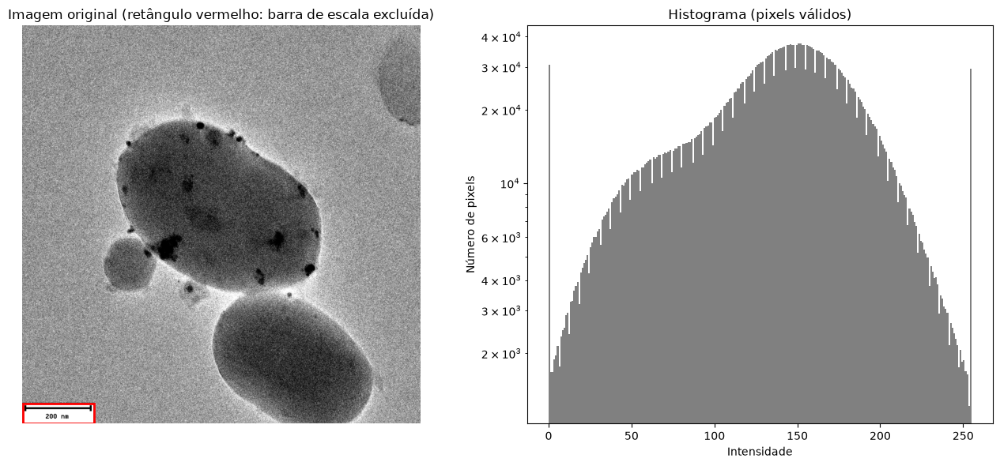

In [13]:
# Barra de escala gravada na imagem, calibração e máscara de validade

comprimento_barra_nm = 200.0    # valor escrito na barra de escala da imagem (nm)
tamanho_pixel_nm = None         # se informado (nm/pixel), substitui a calibração automática pela barra

barra = detectar_barra_de_escala(imagem_raw)
if barra is not None:
    print('Barra de escala detectada: %d pixels  ->  %.0f nm' % (barra['comprimento_px'], comprimento_barra_nm))
    if tamanho_pixel_nm is None:
        tamanho_pixel_nm = comprimento_barra_nm / barra['comprimento_px']
else:
    print('Aviso: barra de escala não detectada. Informe tamanho_pixel_nm para calibrar; sem isso, as escalas serão em pixels.')
if tamanho_pixel_nm is not None:
    print('Tamanho do pixel: %.4f nm/pixel  (campo de visão: %.0f nm)' % (tamanho_pixel_nm, tamanho_pixel_nm * scan_width))

# A região da barra de escala é excluída das estatísticas e preenchida com o fundo vizinho
mascara_valida = construir_mascara_valida(imagem_raw.shape, barra)
ruido_medido = estimar_ruido(imagem_original, mascara_valida)
dataset = preencher_regiao_invalida(imagem_raw, mascara_valida, ruido=ruido_medido)
print('Desvio padrão do ruído estimado: %.2f níveis de cinza' % ruido_medido)

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))
eixos[0].imshow(imagem_raw, cmap='gray')
if barra is not None:
    r0, r1, c0, c1 = barra['caixa']
    eixos[0].add_patch(patches.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='r', linewidth=2))
eixos[0].set_title('Imagem original (retângulo vermelho: barra de escala excluída)')
eixos[0].axis('off')
eixos[1].hist(imagem_raw[mascara_valida].ravel(), bins=256, color='gray')
eixos[1].set_yscale('log')
eixos[1].set_xlabel('Intensidade'); eixos[1].set_ylabel('Número de pixels'); eixos[1].set_title('Histograma (pixels válidos)')
plt.tight_layout(); plt.show()

Pixels quentes corrigidos: 1982


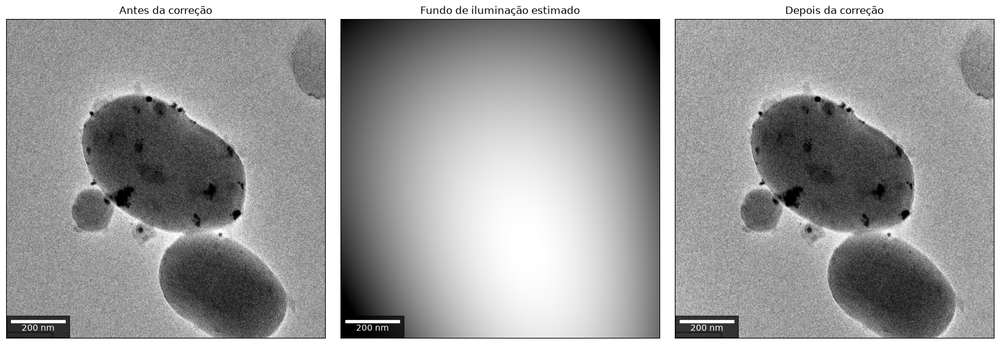

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Antes da correção'}>,
        <Axes: title={'center': 'Fundo de iluminação estimado'}>,
        <Axes: title={'center': 'Depois da correção'}>], dtype=object))

In [14]:
# Remoção de pixels quentes e correção de campo plano (flatfield)

# Pixels quentes (raios X, pixels defeituosos)
dataset, n_quentes = remover_pixels_quentes(dataset, limiar_sigma=6.0, mascara=mascara_valida)
print('Pixels quentes corrigidos:', n_quentes)

# Campo plano
if usar_flatfield_externo:
    flatfield = tifffile.imread(flat_field).astype('float32')
    if flatfield.shape != dataset.shape:
        raise ValueError('O flatfield deve ter a mesma dimensão da imagem: ' + str(flatfield.shape) + ' != ' + str(dataset.shape))
    fundo = flatfield
else:
    fundo = estimar_fundo_polinomial(dataset, mascara_valida, ordem=ordem_polinomio)

dataset_sem_flat = dataset.copy()
dataset = dataset / fundo * fundo[mascara_valida].mean()
dataset_flat = dataset.copy()

mostrar_imagens([dataset_sem_flat, fundo, dataset_flat],
                ['Antes da correção', 'Fundo de iluminação estimado', 'Depois da correção'],
                pixel_nm=tamanho_pixel_nm, mascara=mascara_valida, tamanho=5.5)

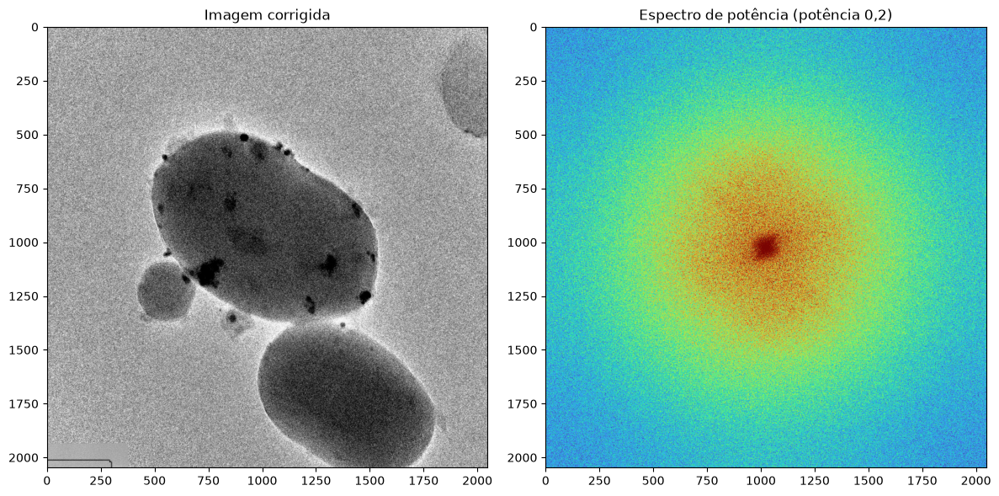

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'Imagem corrigida'}>,
        <Axes: title={'center': 'Espectro de potência (potência 0,2)'}>],
       dtype=object))

In [15]:
# Calcula o espectro de potência médio (análogo ao padrão de difração médio)
dp_mean = espectro_de_potencia(dataset)

# plota a imagem corrigida e o espectro de potência (a barra de escala da própria imagem fica fora da análise)
mostrar_imagens(
    [dataset, dp_mean ** 0.2],
    ['Imagem corrigida', 'Espectro de potência (potência 0,2)'],
    cmaps=['gray', 'turbo'],
    pixel_nm=None,
    mascara=mascara_valida,
    tamanho=6,
)

# Calibração

Raio de corte do sinal = 738.0 pixels da FFT


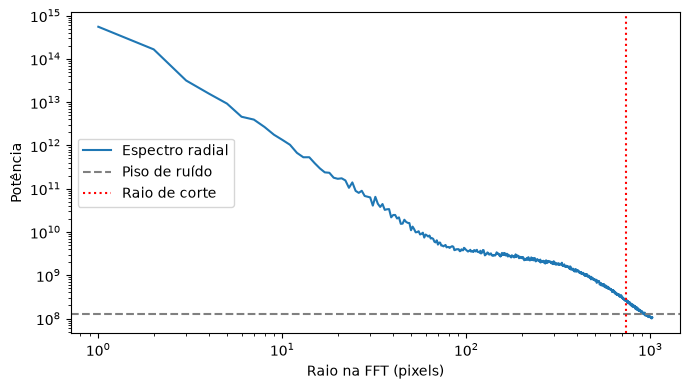

In [16]:
# Estima o raio de corte do sinal no espaço de Fourier
probe_radius_pixels, perfil_psd, piso_ruido = estimar_raio_de_corte(dp_mean)

# Centro do espaço de Fourier (frequência zero)
probe_qx0, probe_qy0 = scan_width // 2, scan_height // 2

print('Raio de corte do sinal = %.1f pixels da FFT' % probe_radius_pixels)

fig, eixo = plt.subplots(figsize=(7, 4))
eixo.loglog(np.arange(1, len(perfil_psd)), perfil_psd[1:], label='Espectro radial')
eixo.axhline(piso_ruido, color='gray', linestyle='--', label='Piso de ruído')
eixo.axvline(probe_radius_pixels, color='r', linestyle=':', label='Raio de corte')
eixo.set_xlabel('Raio na FFT (pixels)'); eixo.set_ylabel('Potência'); eixo.legend()
plt.tight_layout(); plt.show()

In [17]:
# calibração do tamanho de pixel no espaço real, a partir da barra de escala da imagem
# calibração do tamanho de pixel no espaço de Fourier, a partir do tamanho do campo de visão
calibracao = {
    'R_pixel_size': tamanho_pixel_nm if tamanho_pixel_nm is not None else 1.0,
    'R_pixel_units': 'nm' if tamanho_pixel_nm is not None else 'px',
}
calibracao['Q_pixel_size'] = 1.0 / (scan_width * calibracao['R_pixel_size'])
calibracao['Q_pixel_units'] = 'nm^-1' if tamanho_pixel_nm is not None else 'px^-1'
print(calibracao)

# Menor período espacial com sinal acima do ruído (resolução efetiva da imagem)
periodo_minimo = scan_width * calibracao['R_pixel_size'] / probe_radius_pixels
print('Menor período com sinal: %.2f %s' % (periodo_minimo, calibracao['R_pixel_units']))

{'R_pixel_size': 0.5780346820809249, 'R_pixel_units': 'nm', 'Q_pixel_size': 0.0008447265624999999, 'Q_pixel_units': 'nm^-1'}
Menor período com sinal: 1.60 nm


# Imagens virtuais
### Faixas de BF (campo claro, passa-baixa) e ADF (campo escuro, passa-faixa) no espaço de Fourier

Campo claro: raio = 11.8 pixels da FFT | Campo escuro: raios = (14.8, 738.0)


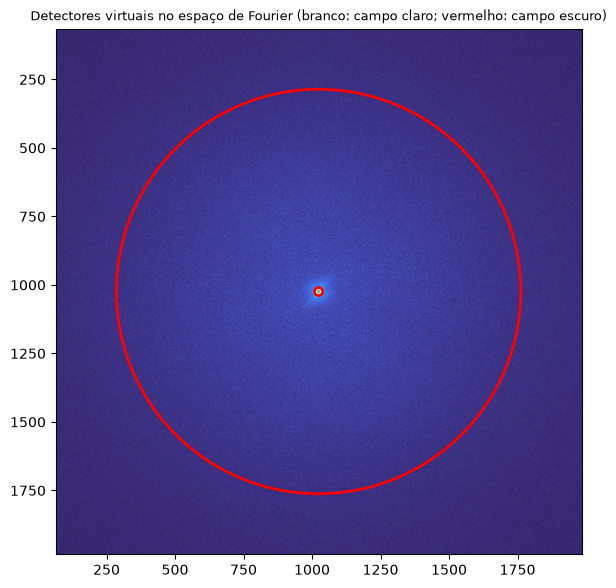

In [18]:
# Cálculo das imagens virtuais de campo claro e de campo escuro

# Estruturas com período maior que este valor (nm; em pixels se não houver calibração) vão para o campo claro
periodo_BF = 100.0
periodo_BF_px = periodo_BF / tamanho_pixel_nm if tamanho_pixel_nm is not None else periodo_BF

# expande o raio em 3 pixels para evitar sobreposição entre os detectores
expand_BF = 3.0

center = (probe_qx0, probe_qy0)
radius_BF = scan_width / periodo_BF_px
radii_DF = (radius_BF + expand_BF, probe_radius_pixels)
if radii_DF[0] >= radii_DF[1]:
    raise ValueError('periodo_BF muito pequeno para o raio de corte do sinal; aumente periodo_BF.')

bright_field = imagem_virtual_fourier(dataset, 'circle', (center, radius_BF))
dark_field = imagem_virtual_fourier(dataset, 'annulus', (center, radii_DF))

print('Campo claro: raio = %.1f pixels da FFT | Campo escuro: raios = (%.1f, %.1f)' % (radius_BF, radii_DF[0], radii_DF[1]))

# posição dos detectores no espaço de Fourier
fig, eixo = plt.subplots(figsize=(6, 6))
eixo.imshow(dp_mean ** 0.2, cmap='turbo')
eixo.add_patch(patches.Circle(center, radius_BF, fill=False, edgecolor='w', linewidth=2, label='Campo claro'))
for raio_i in radii_DF:
    eixo.add_patch(patches.Circle(center, raio_i, fill=False, edgecolor='r', linewidth=2))
eixo.set_title('Detectores virtuais no espaço de Fourier (branco: campo claro; vermelho: campo escuro)', fontsize=9)
eixo.set_xlim(center[0] - 1.3 * radii_DF[1], center[0] + 1.3 * radii_DF[1])
eixo.set_ylim(center[1] + 1.3 * radii_DF[1], center[1] - 1.3 * radii_DF[1])
plt.tight_layout(); plt.show()

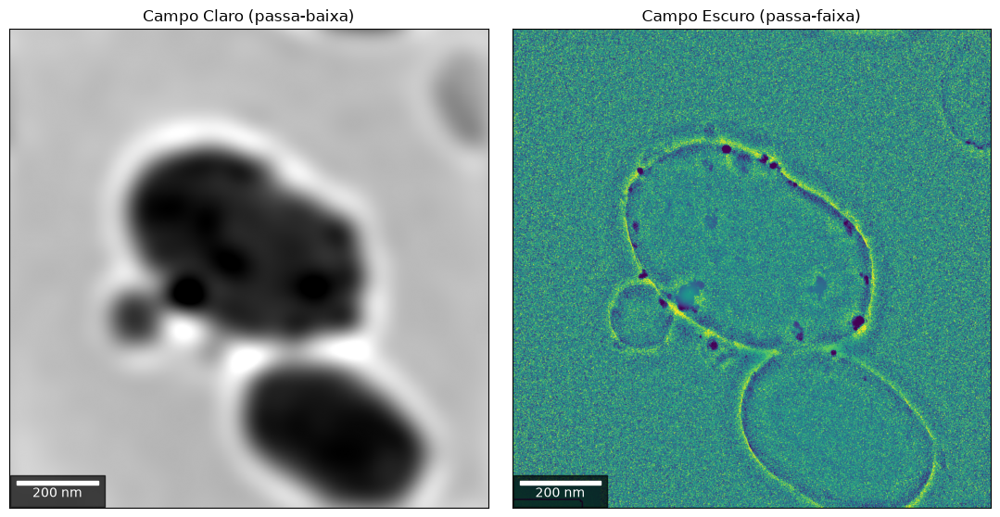

(<Figure size 1100x550 with 2 Axes>,
 array([<Axes: title={'center': 'Campo Claro (passa-baixa)'}>,
        <Axes: title={'center': 'Campo Escuro (passa-faixa)'}>],
       dtype=object))

In [19]:
# plota as imagens virtuais
mostrar_imagens(
    [bright_field, dark_field],
    ['Campo Claro (passa-baixa)', 'Campo Escuro (passa-faixa)'],
    cmaps=['gray', 'viridis'],
    pixel_nm=tamanho_pixel_nm,
    mascara=mascara_valida,
)

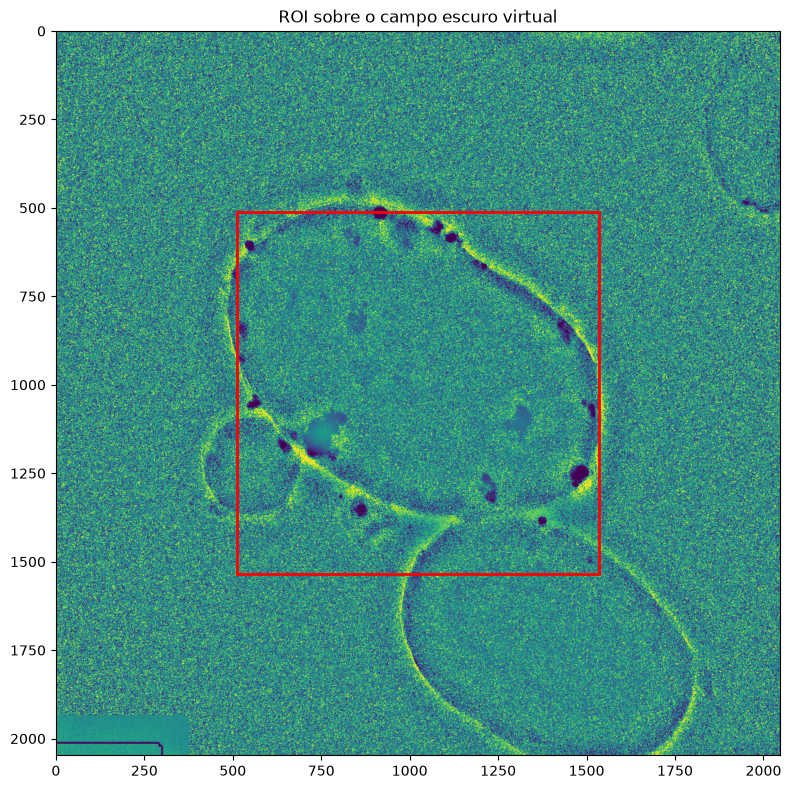

In [20]:
# Verificação da ROI (região de interesse)

# ROI1 = (linha_min, linha_max, coluna_min, coluna_max), em pixels da imagem original.
# Por padrão: a região central (metade da largura e da altura). Para usar a imagem inteira: ROI1 = (0, scan_height, 0, scan_width)
ROI1 = (scan_height // 4, 3 * scan_height // 4, scan_width // 4, 3 * scan_width // 4)

fig, eixo = plt.subplots(figsize=(8, 8))
eixo.imshow(dark_field, cmap='viridis', vmin=np.percentile(dark_field, 0.5), vmax=np.percentile(dark_field, 99.5))
eixo.add_patch(patches.Rectangle((ROI1[2], ROI1[0]), ROI1[3] - ROI1[2], ROI1[1] - ROI1[0], fill=False, edgecolor='r', linewidth=2))
eixo.set_title('ROI sobre o campo escuro virtual')
plt.tight_layout(); plt.show()

In [21]:
# Redução do conjunto de dados (binning, recorte)

dataset_backup = dataset.copy()

# Recorte da imagem (ROI1)
aplicar_recorte = True

# Fatores de binning
R_bin_factor = 1

recorte = (slice(ROI1[0], ROI1[1]), slice(ROI1[2], ROI1[3])) if aplicar_recorte else (slice(None), slice(None))
dataset = agrupar_pixels(dataset_backup[recorte], R_bin_factor)
bright_field_roi = agrupar_pixels(bright_field[recorte], R_bin_factor)
dark_field_roi = agrupar_pixels(dark_field[recorte], R_bin_factor)
mascara_roi = agrupar_pixels(mascara_valida[recorte].astype(np.float32), R_bin_factor) > 0.999
tamanho_pixel_roi = tamanho_pixel_nm * R_bin_factor if tamanho_pixel_nm is not None else None

print('Dimensões após recorte e binning:', dataset.shape)
if tamanho_pixel_roi is not None:
    print('Tamanho do pixel: %.4f nm' % tamanho_pixel_roi)

Dimensões após recorte e binning: (1024, 1024)
Tamanho do pixel: 0.5780 nm


In [22]:
# Salva a região recortada (desative o comentário se quiser gravar)
# tifffile.imwrite(
#     os.path.splitext(filename)[0] + '_recorte.tif',
#     dataset.astype(np.float32),
# )

In [23]:
# Parâmetros - Versão A: SCIENTIFIC
parametros_scientific = {
    'black_point': 0.3,
    'white_point': 99.7,
    'gamma': 0.98,

    'denoise_strength': 'auto',   # 'auto' = proporcional ao ruído medido (ou um valor fixo de h)
    'denoise_fator': 0.6,

    'clahe_limit': 1.0,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.05,
    'smooth_sigma': 0.6,

    'sharp_strength': 0.25,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.1, 99.9),
}

# Parâmetros - Versão B: VISUAL
parametros_visual = {
    'black_point': 0.5,
    'white_point': 99.7,
    'gamma': 0.95,

    'denoise_strength': 'auto',
    'denoise_fator': 1.0,

    'clahe_limit': 1.5,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.15,
    'smooth_sigma': 0.8,

    'sharp_strength': 0.40,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.2, 99.8),
}

Força do filtro Non-Local Means (h): scientific = 7.32 | visual = 12.22
Versão SCIENTIFIC | média = 0.4483 | desvio padrão = 0.2446 | mín = 0.000 | máx = 1.000
Versão VISUAL | média = 0.4686 | desvio padrão = 0.2535 | mín = 0.000 | máx = 1.000


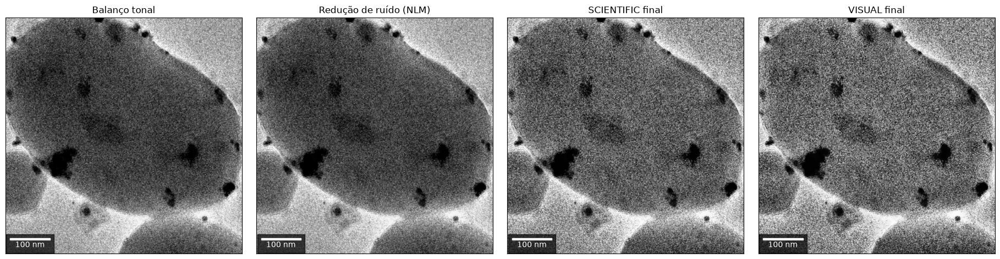

(<Figure size 1840x460 with 4 Axes>,
 array([<Axes: title={'center': 'Balanço tonal'}>,
        <Axes: title={'center': 'Redução de ruído (NLM)'}>,
        <Axes: title={'center': 'SCIENTIFIC final'}>,
        <Axes: title={'center': 'VISUAL final'}>], dtype=object))

In [24]:
# Execução das duas versões sobre a região de interesse

resultados_scientific = processar_imagem(dataset, parametros_scientific, mascara_roi)
resultados_visual = processar_imagem(dataset, parametros_visual, mascara_roi)

dataset_norm = resultados_scientific['balance']
dataset_balance = resultados_scientific['balance']
dataset_gamma = resultados_scientific['gamma']
dataset_denoised = resultados_scientific['denoised']
dataset_eq = resultados_scientific['clahe']
dataset_clahe = resultados_scientific['clahe']
dataset_smooth = resultados_scientific['smooth']
dataset_sharp = resultados_scientific['sharp']

dataset_scientific = resultados_scientific['final']
dataset_visual = resultados_visual['final']

print('Força do filtro Non-Local Means (h): scientific = %.2f | visual = %.2f' % (resultados_scientific['h_nlm'], resultados_visual['h_nlm']))
for nome, img in (('SCIENTIFIC', dataset_scientific), ('VISUAL', dataset_visual)):
    print('Versão', nome, '| média = %.4f | desvio padrão = %.4f | mín = %.3f | máx = %.3f' % (img.mean(), img.std(), img.min(), img.max()))

mostrar_imagens([dataset_norm, dataset_denoised, dataset_scientific, dataset_visual],
                ['Balanço tonal', 'Redução de ruído (NLM)', 'SCIENTIFIC final', 'VISUAL final'],
                pixel_nm=tamanho_pixel_roi, vlims=[(0, 1)] * 4, tamanho=4.6)

# Cálculo do gradiente (análogo ao CoM)
### Campo de gradiente e imagem integrada (DPC)

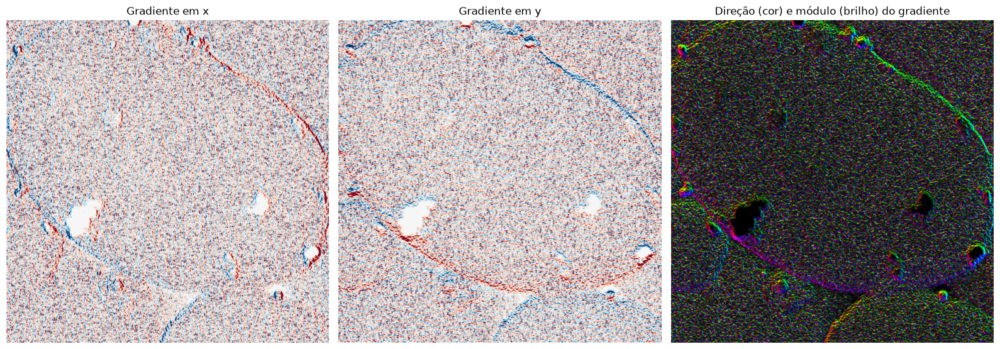

In [25]:
# Inicializa a reconstrução DPC: campo de gradiente da imagem sem ruído (análogo ao campo de CoM)

sigma_gradiente = 1.5      # pixels (suavização antes de derivar)
gx, gy = campo_de_gradiente(dataset_denoised, sigma_gradiente)

dpc = SimpleNamespace(
    datacube=dataset_denoised,
    name='dpc_image',
    gx=gx,
    gy=gy,
    # force_com_rotation = 180+    (não se aplica: o gradiente de uma imagem escalar não tem rotação)
)

fig, eixos = plt.subplots(1, 3, figsize=(16, 5.5))
v = np.percentile(np.abs(gx), 99)
eixos[0].imshow(gx, cmap='RdBu_r', vmin=-v, vmax=v); eixos[0].set_title('Gradiente em x')
eixos[1].imshow(gy, cmap='RdBu_r', vmin=-v, vmax=v); eixos[1].set_title('Gradiente em y')
eixos[2].imshow(cor_do_gradiente(gx, gy)); eixos[2].set_title('Direção (cor) e módulo (brilho) do gradiente')
for e in eixos: e.axis('off')
plt.tight_layout(); plt.show()

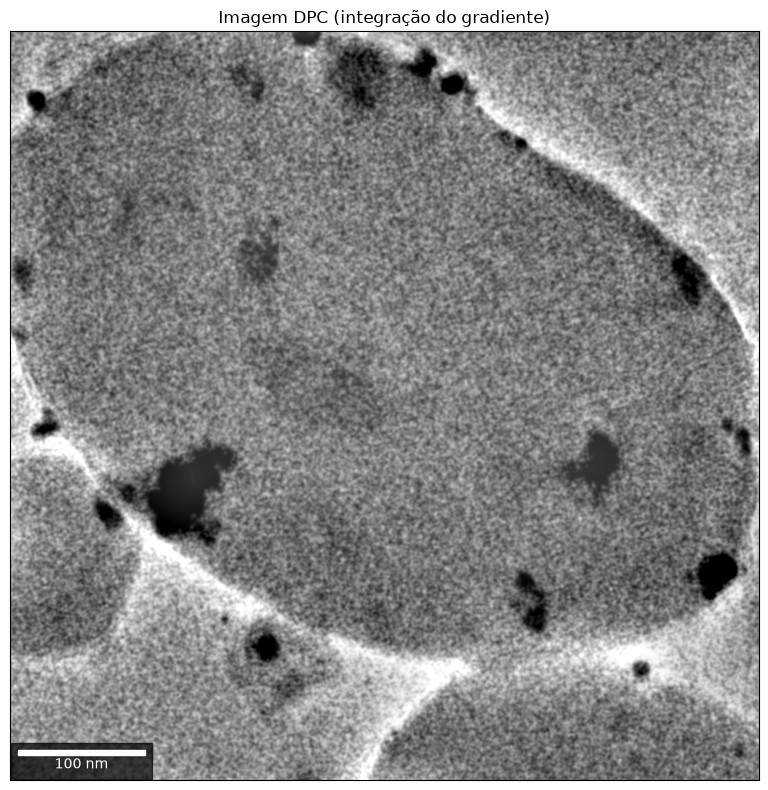

(<Figure size 800x800 with 1 Axes>,
 array([<Axes: title={'center': 'Imagem DPC (integração do gradiente)'}>],
       dtype=object))

In [26]:
# Reconstrução DPC: compressão do gradiente e integração por Fourier

beta_compressao = 0.85     # 1,0 = sem compressão; valores menores atenuam bordas fortes e realçam detalhes fracos
q_highpass = 3.0           # pixels da FFT; suprime as frequências mais baixas

gx_c, gy_c = comprimir_gradiente(dpc.gx, dpc.gy, beta=beta_compressao)
dpc.object_phase = integrar_gradiente_fourier(gx_c, gy_c, q_highpass=q_highpass)

mostrar_imagens([dpc.object_phase], ['Imagem DPC (integração do gradiente)'], pixel_nm=tamanho_pixel_roi,
                mascara=mascara_roi, tamanho=8)

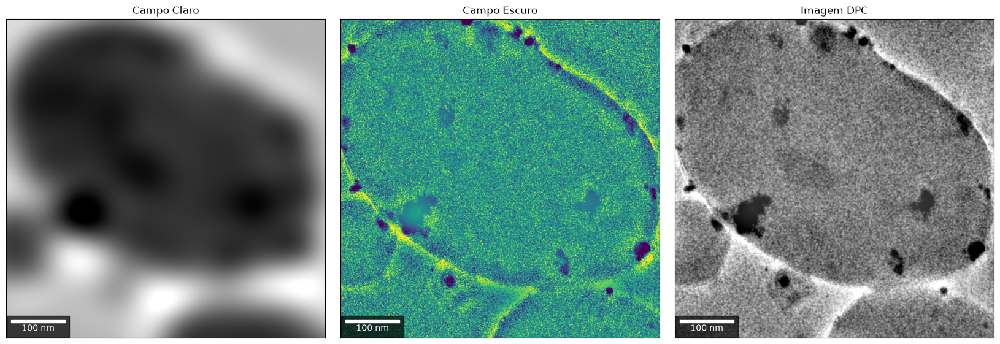

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Claro'}>,
        <Axes: title={'center': 'Campo Escuro'}>,
        <Axes: title={'center': 'Imagem DPC'}>], dtype=object))

In [27]:
mostrar_imagens(
    [bright_field_roi, dark_field_roi, dpc.object_phase],
    ['Campo Claro', 'Campo Escuro', 'Imagem DPC'],
    cmaps=['gray', 'viridis', 'gray'],
    pixel_nm=tamanho_pixel_roi,
    mascara=mascara_roi,
)

Intensidade do fundo (I0): 171.08


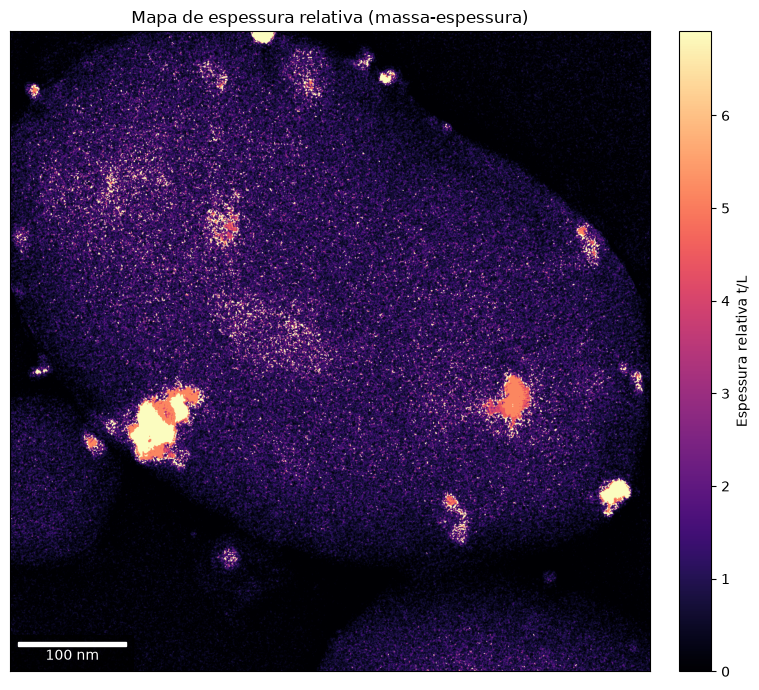

In [28]:
# Mapa relativo de espessura (contraste de massa-espessura): t/L = -ln(I/I0)

# Suaviza em escala linear de intensidade (sem gama nem CLAHE)
escala_lin = 1.0 / np.percentile(dataset, 99.9)
linear = np.clip(dataset * escala_lin, 0, 1)
linear = reduzir_ruido(linear, resultados_scientific['h_nlm']) / escala_lin

# I0 = intensidade do fundo (pico mais claro do histograma)
contagem, bordas = np.histogram(linear[mascara_roi], bins=256)
contagem = ndimage.uniform_filter1d(contagem.astype(float), 5)
centros = 0.5 * (bordas[:-1] + bordas[1:])
candidatos = [i for i in range(1, 255) if contagem[i] >= contagem[i - 1] and contagem[i] >= contagem[i + 1] and contagem[i] > 0.3 * contagem.max()]
I0 = float(centros[candidatos[-1]]) if candidatos else float(np.percentile(linear[mascara_roi], 95))
print('Intensidade do fundo (I0): %.2f' % I0)

espessura_relativa = -np.log(np.clip(linear / I0, 1e-3, None))
espessura_relativa = np.clip(espessura_relativa, 0, None)

fig, eixo = plt.subplots(figsize=(8, 7))
im = eixo.imshow(espessura_relativa, cmap='magma', vmin=0, vmax=np.percentile(espessura_relativa[mascara_roi], 99.5))
plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04, label='Espessura relativa t/L')
eixo.set_title('Mapa de espessura relativa (massa-espessura)')
if tamanho_pixel_roi is not None:
    adicionar_barra_de_escala(eixo, tamanho_pixel_roi, dataset.shape[1])
    eixo.set_xticks([]); eixo.set_yticks([])
plt.tight_layout(); plt.show()

# Restauração iterativa (análoga à pticografia)

In [29]:
# Imagem de entrada da restauração (análogo ao bin_Q aplicado antes da pticografia)

Q_bin_factor = 1     # use 2 para reduzir o tempo de cálculo (perde resolução)
dataset_ptycho = agrupar_pixels(dataset_denoised, Q_bin_factor) + 0.02    # deslocamento pequeno: evita divisão por zero
tamanho_pixel_ptycho = tamanho_pixel_roi * Q_bin_factor if tamanho_pixel_roi is not None else None

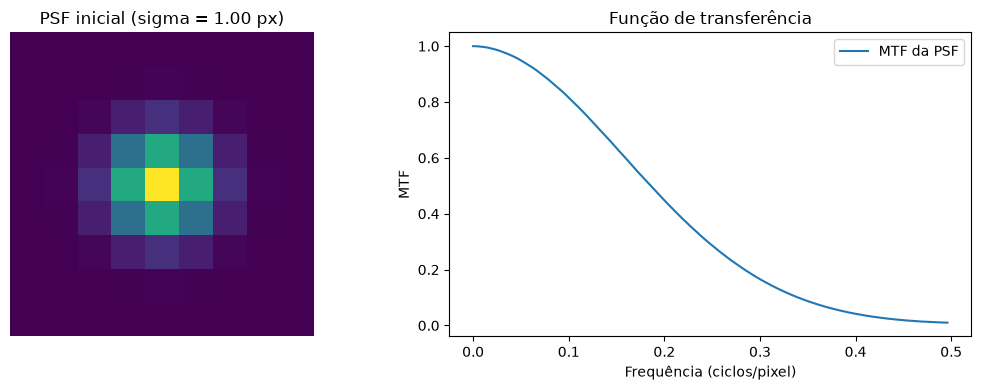

In [30]:
# Restauração Richardson-Lucy com regularização TV (single-slice: um único plano de imagem)

# definição da PSF (análoga à definição da sonda)
psf_sigma = 1.0                     # pixels - valor inicial, refinado na etapa 2
object_padding_px = (16, 16)        # preenchimento por reflexão (evita artefatos de borda)
semiangle_cutoff = probe_radius_pixels     # pixels da FFT (raio de corte do sinal)

# Pré-processamento
ptycho = criar_restauracao(
    dataset_ptycho,
    psf_sigma=psf_sigma,
    padding=object_padding_px,
)

# mostra a PSF e sua função de transferência (MTF) comparadas ao espectro da imagem
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].imshow(ptycho.probe, cmap='viridis'); eixos[0].set_title('PSF inicial (sigma = %.2f px)' % psf_sigma); eixos[0].axis('off')
mtf = np.abs(np.fft.fftshift(np.fft.fft2(ptycho.probe, s=(256, 256))))
f_mtf = np.arange(128) / 256.0
eixos[1].plot(f_mtf, perfil_radial(mtf)[:128], label='MTF da PSF')
eixos[1].set_xlabel('Frequência (ciclos/pixel)'); eixos[1].set_ylabel('MTF'); eixos[1].set_title('Função de transferência'); eixos[1].legend()
plt.tight_layout(); plt.show()

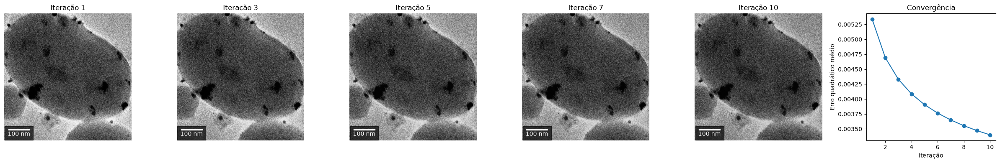

In [31]:
# Etapa 1: iterações com a PSF inicial

ptycho = reconstruir(
    ptycho,
    reset = True,
    num_iter = 10,
    step_size = 1.0,
)
visualizar_iteracoes(ptycho.iterations, ptycho.error_iterations, pixel_nm=tamanho_pixel_ptycho)

Ajuste da PSF inconclusivo (sigma = 0.0); mantendo psf_sigma = 1.00


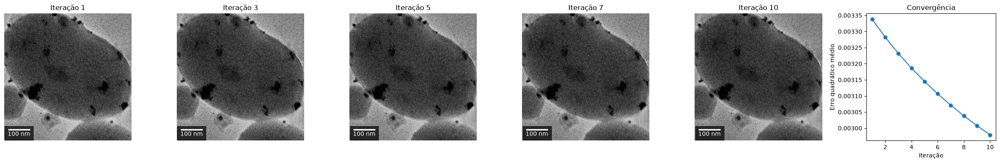

In [32]:
# Etapa 2: ajuste da PSF a partir do espectro de potência (análogo ao ajuste das aberrações da sonda)

sigma_estimado, raios_ajuste, perfil_modelo = ajustar_sigma_psf(dp_mean, probe_radius_pixels, piso_ruido)
if sigma_estimado is None or not (0.3 <= sigma_estimado <= 6.0):
    print('Ajuste da PSF inconclusivo (sigma = %s); mantendo psf_sigma = %.2f' % (sigma_estimado, psf_sigma))
else:
    print('Sigma da PSF estimado pelo espectro: %.2f pixels' % sigma_estimado)
    ptycho.probe = psf_gaussiana(sigma_estimado)
    ptycho.psf_sigma = sigma_estimado

    fig, eixo = plt.subplots(figsize=(7, 4))
    eixo.loglog(np.arange(1, len(perfil_psd)), perfil_psd[1:], label='Espectro radial medido')
    eixo.loglog(raios_ajuste, perfil_modelo, 'r', label='Modelo ajustado')
    eixo.axhline(piso_ruido, color='gray', linestyle='--', label='Piso de ruído')
    eixo.set_xlabel('Raio na FFT (pixels)'); eixo.set_ylabel('Potência'); eixo.legend()
    plt.tight_layout(); plt.show()

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
)
visualizar_iteracoes(ptycho.iterations[-10:], ptycho.error_iterations[-10:], pixel_nm=tamanho_pixel_ptycho)

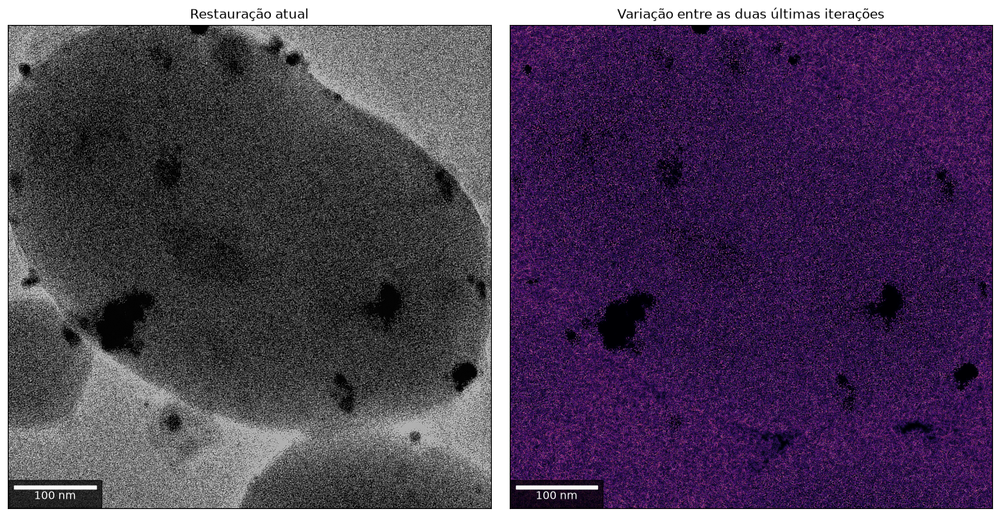

(<Figure size 1300x650 with 2 Axes>,
 array([<Axes: title={'center': 'Restauração atual'}>,
        <Axes: title={'center': 'Variação entre as duas últimas iterações'}>],
       dtype=object))

In [33]:
# Etapa 3: mapa de variação entre as duas últimas iterações (onde a solução ainda muda)

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
)
variacao = np.abs(ptycho.iterations[-1] - ptycho.iterations[-2])

mostrar_imagens([ptycho.object, variacao], ['Restauração atual', 'Variação entre as duas últimas iterações'],
                cmaps=['gray', 'magma'], pixel_nm=tamanho_pixel_ptycho, tamanho=6.5)

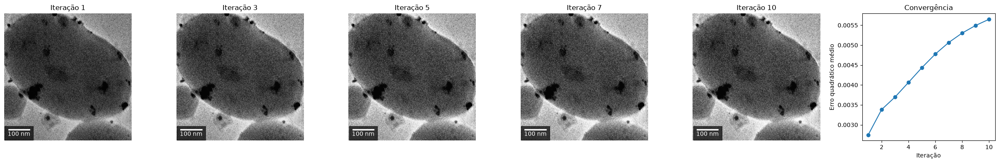

In [34]:
# Etapa 4: restauração final com regularização de variação total (TV)

tv_denoise_weight = 0.08

ptycho = reconstruir(
    ptycho,
    reset = False,
    num_iter = 10,
    step_size = 1.0,
    tv_denoise_weight = tv_denoise_weight,
)
visualizar_iteracoes(ptycho.iterations[-10:], ptycho.error_iterations[-10:], pixel_nm=tamanho_pixel_ptycho)

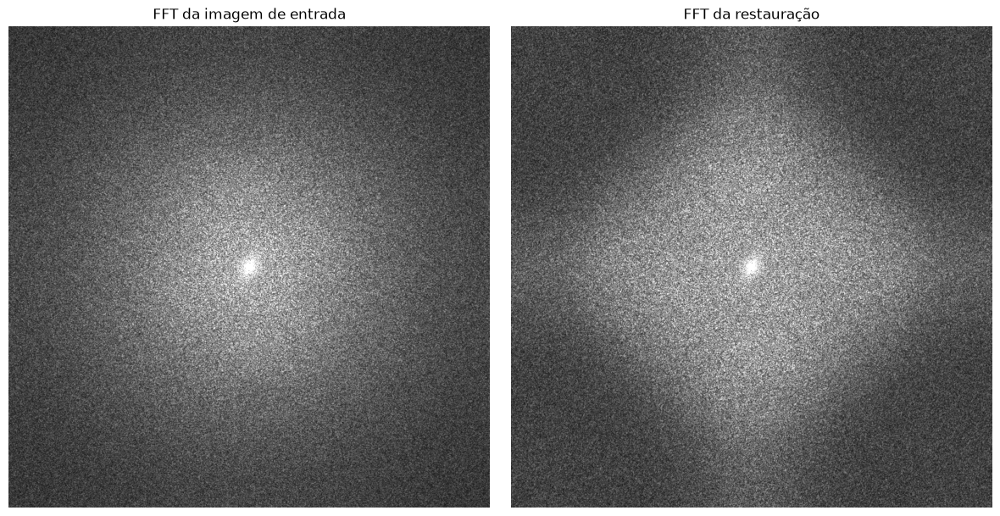

In [35]:
# FFT da imagem antes e depois da restauração
mostrar_fft_objeto(
    dataset_ptycho,
    ptycho.object,
    figsize = (12, 6),
    power = 0.5,
)

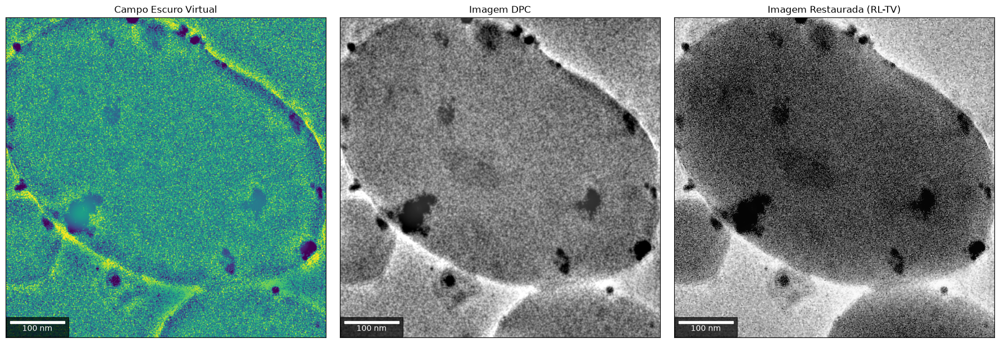

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Escuro Virtual'}>,
        <Axes: title={'center': 'Imagem DPC'}>,
        <Axes: title={'center': 'Imagem Restaurada (RL-TV)'}>],
       dtype=object))

In [36]:
obj = ptycho.object
pixelsize = tamanho_pixel_ptycho if tamanho_pixel_ptycho is not None else 1

# #reamostragem
# zoom_factor=(4,4)
# obj2 = ndimage.zoom(obj, zoom_factor)
# pixelsize_obj2 = pixelsize/zoom_factor[0]

mostrar_imagens(
    [agrupar_pixels(dark_field_roi, Q_bin_factor), agrupar_pixels(dpc.object_phase, Q_bin_factor), obj],
    ['Campo Escuro Virtual', 'Imagem DPC', 'Imagem Restaurada (RL-TV)'],
    cmaps=['viridis', 'gray', 'gray'],
    pixel_nm=tamanho_pixel_ptycho,
    tamanho=6,
)

# Comparação final e salvamento dos resultados

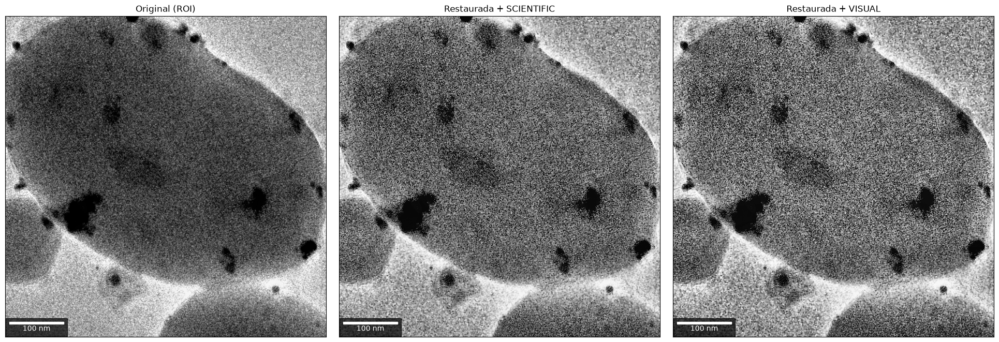

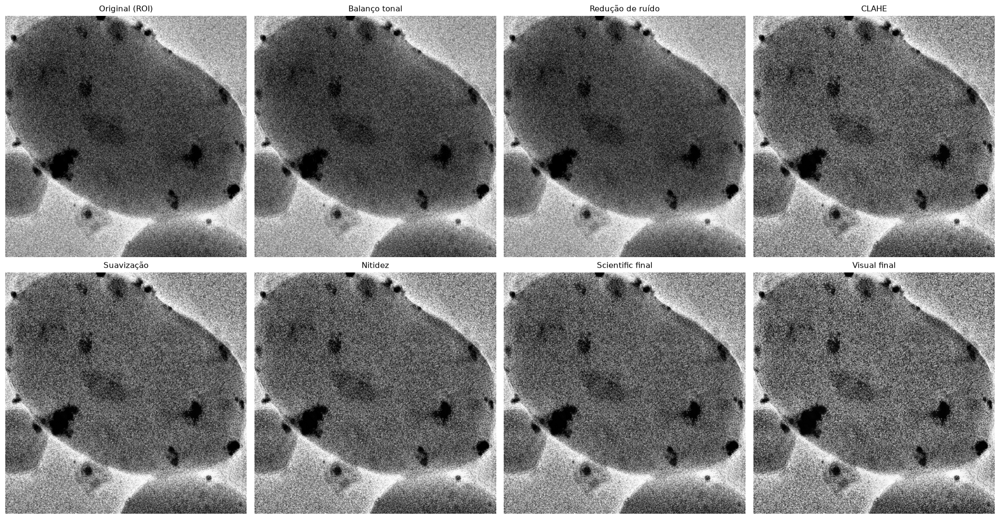

In [37]:
# Realce final da imagem restaurada nas versões SCIENTIFIC e VISUAL

restaurada_scientific = realce_final(obj, parametros_scientific)
restaurada_visual = realce_final(obj, parametros_visual)
referencia = normalizar_percentis(dataset_ptycho - 0.02, (0.5, 99.7))

# Comparação geral
mostrar_imagens(
    [referencia, restaurada_scientific, restaurada_visual],
    ['Original (ROI)', 'Restaurada + SCIENTIFIC', 'Restaurada + VISUAL'],
    pixel_nm=tamanho_pixel_ptycho, vlims=[(0, 1)] * 3, tamanho=6.5,
)

# Comparação das etapas de processamento
etapas = [
    (referencia, 'Original (ROI)'),
    (dataset_balance, 'Balanço tonal'),
    (dataset_denoised, 'Redução de ruído'),
    (dataset_clahe, 'CLAHE'),
    (dataset_smooth, 'Suavização'),
    (dataset_sharp, 'Nitidez'),
    (dataset_scientific, 'Scientific final'),
    (dataset_visual, 'Visual final'),
]
fig, eixos = plt.subplots(2, 4, figsize=(19, 10))
for eixo, (img, titulo) in zip(eixos.flat, etapas):
    eixo.imshow(img, cmap='gray', vmin=0, vmax=1)
    eixo.set_title(titulo, fontsize=11)
    eixo.axis('off')
plt.tight_layout(); plt.show()

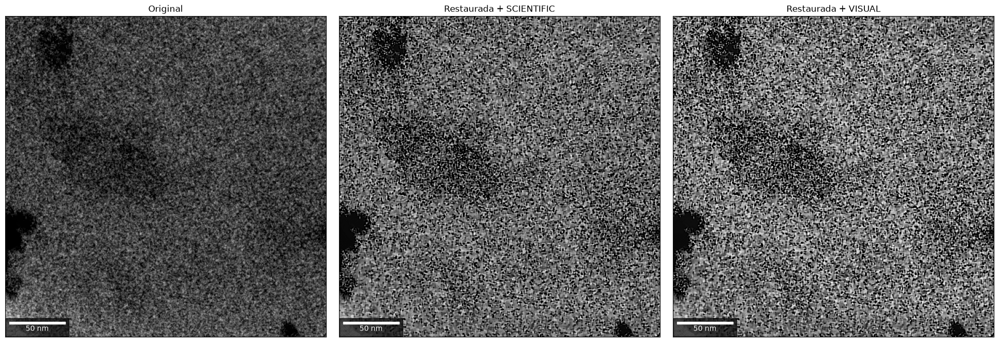

(<Figure size 1950x650 with 3 Axes>,
 array([<Axes: title={'center': 'Original'}>,
        <Axes: title={'center': 'Restaurada + SCIENTIFIC'}>,
        <Axes: title={'center': 'Restaurada + VISUAL'}>], dtype=object))

In [38]:
# Comparação de uma região da microestrutura (recorte central de até 500 x 500 pixels)

alt, larg = obj.shape
meio_y, meio_x = alt // 2, larg // 2
meia = min(250, alt // 2, larg // 2)
y1, y2, x1, x2 = meio_y - meia, meio_y + meia, meio_x - meia, meio_x + meia

mostrar_imagens(
    [referencia[y1:y2, x1:x2], restaurada_scientific[y1:y2, x1:x2], restaurada_visual[y1:y2, x1:x2]],
    ['Original', 'Restaurada + SCIENTIFIC', 'Restaurada + VISUAL'],
    pixel_nm=tamanho_pixel_ptycho, vlims=[(0, 1)] * 3, tamanho=6.5,
)

In [39]:
# Salvamento dos resultados (float32, mantendo a faixa normalizada de 0 a 1) na pasta do notebook

base = os.path.splitext(filename)[0]
arquivos = {
    base + '_PLUS_SCIENTIFIC.tif': dataset_scientific,
    base + '_PLUS_VISUAL.tif': dataset_visual,
    base + '_RESTAURADA_SCIENTIFIC.tif': restaurada_scientific,
    base + '_RESTAURADA_VISUAL.tif': restaurada_visual,
    base + '_DPC.tif': dpc.object_phase,
    base + '_ESPESSURA_RELATIVA.tif': espessura_relativa,
}
for caminho_saida, imagem_saida in arquivos.items():
    tifffile.imwrite(caminho_saida, np.asarray(imagem_saida, dtype=np.float32), photometric='minisblack')

print('ARQUIVOS SALVOS:')
for caminho_saida in arquivos:
    print(caminho_saida)

ARQUIVOS SALVOS:
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_PLUS_SCIENTIFIC.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_PLUS_VISUAL.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_RESTAURADA_SCIENTIFIC.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_RESTAURADA_VISUAL.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_DPC.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_ESPESSURA_RELATIVA.tif
